# 06 — Modélisation avancée et gestion du déséquilibre

**Objectifs**
1. Comparer trois familles de modèles à base d'arbres : **Random Forest**, **XGBoost**, **LightGBM** ;
2. Répondre à la **question de recherche (RQ)** du cadrage : quelle stratégie de gestion du déséquilibre (aucune, pondération, sous-échantillonnage, SMOTE) offre le meilleur compromis performance / coût de calcul ?
3. **Régler les hyperparamètres** du meilleur modèle par validation croisée **temporelle** ;
4. Mener l'**étude de robustesse** : performance avec toutes les variables (`complet`) et sans les variables de soldes (`transaction`).

**Objectifs à battre (notebook 05, validation)** : PR-AUC **0,992** (règle « compte vidé ») sur le jeu complet, **0,050** (régression logistique) sur le jeu transaction.

**Protocole** : apprentissage sur le **train** (jours 0-12), comparaison sur la **validation** (jours 13-14). Le **test** reste intact jusqu'à la Phase 8.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, uniform
from sklearn.metrics import average_precision_score
from sklearn.model_selection import RandomizedSearchCV

from src.config import TARGET, MODELS_DIR, RANDOM_STATE
from src.split import load_split
from src.features import build_preprocessor
from src.baselines import RegleCompteVide, make_logistic_regression
from src.models import (MODEL_NAMES, MODEL_LABELS, IMBALANCE_STRATEGIES, make_model,
                        positive_weight, temporal_cv_folds)
from src.evaluate import compare_models, bootstrap_pr_auc, plot_pr_curves, save_results
from src.viz import set_style, save_fig, TEXT_PRIMARY, TEXT_SECONDARY, SEQUENTIAL_CMAP

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

train, val = load_split("train"), load_split("val")
y_train, y_val = train[TARGET].to_numpy(), val[TARGET].to_numpy()
amounts_val = val["amount"].to_numpy()
POS_WEIGHT = positive_weight(y_train)
print(f"Train : {len(train):,} transactions, {y_train.sum():,} fraudes")
print(f"Val   : {len(val):,} transactions, {y_val.sum():,} fraudes")
print(f"Poids d'équilibrage des classes (légitimes / fraudes) : {POS_WEIGHT:.0f}")

Train : 1,917,584 transactions, 3,511 fraudes
Val   : 346,348 transactions, 498 fraudes
Poids d'équilibrage des classes (légitimes / fraudes) : 545


### Calcul des variables une seule fois

Le constructeur de variables est **sans état** (notebook 04) : appliquer le prétraitement une fois, puis entraîner les modèles sur les variables calculées, donne **exactement** le même résultat que de refaire le prétraitement à chaque entraînement, sans aucun risque de fuite. On gagne seulement du temps sur la vingtaine d'entraînements de ce notebook. Les modèles finaux, eux, sont sauvegardés sous forme de **pipelines complets** (données brutes → prédiction).

In [2]:
X = {}
for fs in ["complet", "transaction"]:
    pre = build_preprocessor(fs)
    X[fs] = {"train": pre.fit_transform(train), "val": pre.transform(val)}
    print(f"{fs:<12} : {X[fs]['train'].shape[1]:>2} variables")

def fit_and_score(name, feature_set, imbalance, **params):
    """Entraîne un modèle sur le train et renvoie (modèle, scores val, durée en s)."""
    model = make_model(name, feature_set, imbalance, pos_weight=POS_WEIGHT,
                       preprocess=False, **params)
    start = time.perf_counter()
    model.fit(X[feature_set]["train"], y_train)
    duration = time.perf_counter() - start
    return model, model.predict_proba(X[feature_set]["val"])[:, 1], duration

complet      : 15 variables


transaction  :  5 variables


## 1. Diagnostic préalable : l'instabilité de LightGBM

Les premiers essais ont révélé un comportement anormal de LightGBM : avec ses réglages par défaut, il **s'effondre** dans deux situations, alors que XGBoost fonctionne. Plutôt que de l'écarter, on a cherché la cause. Deux mécanismes distincts ont été identifiés et corrigés dans `src/models.py` :

1. **Pondération des classes + initialisation** : par défaut, LightGBM initialise ses prédictions au log-odds de la prévalence **brute** (≈ −6,3, soit 0,18 % de fraude), sans tenir compte du poids des fraudes. Avec un poids de ~545, l'optimum pondéré est proche de 0 : le modèle part très loin de sa cible, et les premiers pas de Newton (gradient / hessienne) sont démesurés. ➜ Correctif : `boost_from_average=False` quand on pondère.
2. **Données presque séparables** (jeu `complet`) : les feuilles pures ont une hessienne p(1−p) quasi nulle, donc des valeurs de feuille énormes. Le garde-fou `min_child_weight` vaut 1e-3 par défaut dans LightGBM, contre 1 dans XGBoost. ➜ Correctif : `min_child_weight=1`.

La cellule suivante reproduit chaque problème, puis montre l'effet du correctif.

In [3]:
diag_configs = [
    ("transaction", "ponderation", {"boost_from_average": True}, "Réglage par défaut"),
    ("transaction", "ponderation", {}, "Correctif (boost_from_average=False)"),
    ("complet", "aucune", {"min_child_weight": 1e-3}, "Réglage par défaut"),
    ("complet", "aucune", {}, "Correctif (min_child_weight=1)"),
]
rows = []
for fs, imb, params, label in diag_configs:
    model, s, _ = fit_and_score("lightgbm", fs, imb, **params)
    s_train = model.predict_proba(X[fs]["train"])[:, 1]
    rows.append({"jeu": fs, "strategie": imb, "configuration": label,
                 "pr_auc_train": average_precision_score(y_train, s_train),
                 "pr_auc_val": average_precision_score(y_val, s)})
diag = pd.DataFrame(rows)
diag

,jeu,strategie,configuration,pr_auc_train,pr_auc_val
0,transaction,ponderation,Réglage par défaut,0.0119,0.0075
1,transaction,ponderation,Correctif (boost_from_average=False),0.2814,0.3678
2,complet,aucune,Réglage par défaut,0.3685,0.3774
3,complet,aucune,Correctif (min_child_weight=1),1.0000,1.0000


**Lecture**
- **Pondération** : avec le réglage par défaut, LightGBM obtient une PR-AUC de **0,008** sur la validation, soit à peine plus que le hasard (0,0014). La PR-AUC sur le **train** est tout aussi basse (0,012) : il ne s'agit **pas** de sur-apprentissage mais d'un **échec de l'optimisation**. Avec `boost_from_average=False`, le même modèle atteint **0,368**.
- **Jeu complet** : avec `min_child_weight=1e-3`, LightGBM plafonne à 0,377, très loin de la règle d'une ligne (0,992). Avec `min_child_weight=1`, il sépare parfaitement les classes (1,000).
- ➡️ Enseignement méthodologique : un mauvais score n'est pas forcément une limite du modèle. Comparer la performance **train** et **validation** permet de distinguer un problème d'optimisation (les deux sont mauvaises) d'un sur-apprentissage (train bon, validation mauvaise). Sans ce diagnostic, on aurait conclu à tort que « la pondération ne marche pas avec LightGBM ».

## 2. Jeu `transaction` : modèles × stratégies de déséquilibre (RQ)

C'est le cœur de la comparaison : sans les variables de soldes, le problème est difficile (logistique : PR-AUC 0,05) et les écarts entre méthodes sont réellement informatifs.

**Stratégies comparées** (le rééchantillonnage est appliqué **uniquement au train**, à l'intérieur du pipeline) :

| Stratégie | Principe | Paramètre |
|---|---|---|
| `aucune` | données telles quelles | — |
| `ponderation` | une fraude pèse autant que ~545 légitimes dans la perte | poids = légitimes / fraudes |
| `sous_echantillonnage` | on retire au hasard des légitimes | 1 fraude pour 10 légitimes |
| `smote` | on crée des fraudes synthétiques par interpolation | 1 fraude pour 10 légitimes |

Les hyperparamètres sont ceux par défaut de `src/models.py` (identiques pour toutes les stratégies) : on compare les **stratégies**, pas des modèles réglés différemment. Le temps d'entraînement est mesuré, car la RQ porte aussi sur le **coût de calcul**.

In [4]:
rows, scores_tr = [], {}
for name in MODEL_NAMES:
    for imb in IMBALANCE_STRATEGIES:
        _, s, duration = fit_and_score(name, "transaction", imb)
        scores_tr[(name, imb)] = s
        rows.append({"modele": MODEL_LABELS[name], "strategie": imb,
                     "pr_auc": average_precision_score(y_val, s), "duree_s": duration})
        print(f"{MODEL_LABELS[name]:<14} {imb:<21} PR-AUC = {rows[-1]['pr_auc']:.4f}   ({duration:6.1f} s)")

strategies = pd.DataFrame(rows)
_ = save_results(strategies.set_index(["modele", "strategie"]).reset_index(level=1),
                 "06_strategies_transaction")

Random Forest  aucune                PR-AUC = 0.2767   (  79.7 s)


Random Forest  ponderation           PR-AUC = 0.3063   (  51.7 s)


Random Forest  sous_echantillonnage  PR-AUC = 0.3594   (   0.7 s)


Random Forest  smote                 PR-AUC = 0.1584   (  90.0 s)


XGBoost        aucune                PR-AUC = 0.3642   (  21.1 s)


XGBoost        ponderation           PR-AUC = 0.3465   (  19.9 s)


... (2 outputs left out)

LightGBM       aucune                PR-AUC = 0.3605   (   9.2 s)


LightGBM       ponderation           PR-AUC = 0.3678   (  10.3 s)


LightGBM       sous_echantillonnage  PR-AUC = 0.3298   (   0.8 s)


LightGBM       smote                 PR-AUC = 0.3568   (  10.8 s)


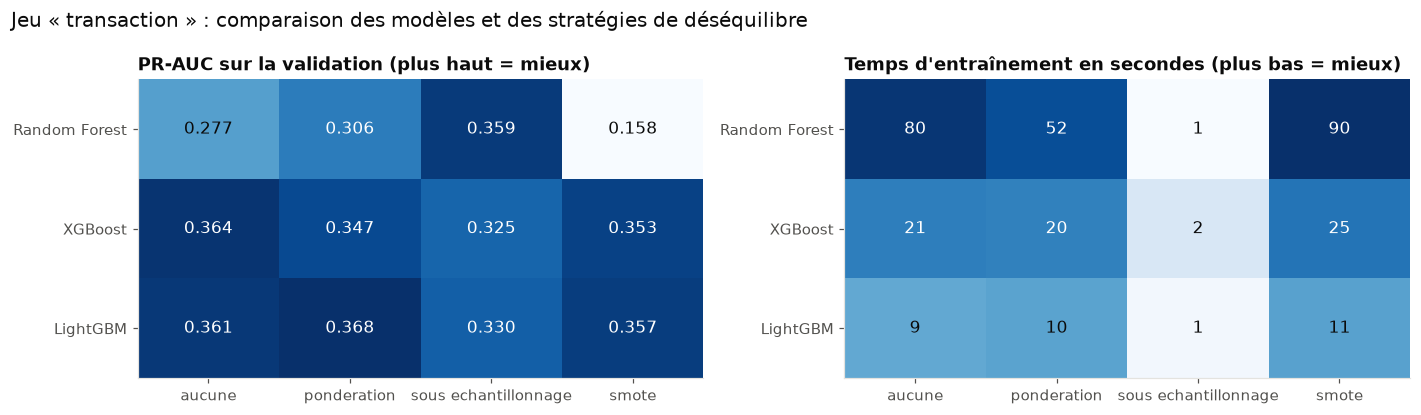

In [5]:
pr_grid = strategies.pivot(index="modele", columns="strategie", values="pr_auc")
time_grid = strategies.pivot(index="modele", columns="strategie", values="duree_s")
order_rows = [MODEL_LABELS[m] for m in MODEL_NAMES]
pr_grid, time_grid = pr_grid.loc[order_rows, IMBALANCE_STRATEGIES], time_grid.loc[order_rows, IMBALANCE_STRATEGIES]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, grid, title, fmt in [
    (axes[0], pr_grid, "PR-AUC sur la validation (plus haut = mieux)", "{:.3f}"),
    (axes[1], time_grid, "Temps d'entraînement en secondes (plus bas = mieux)", "{:.0f}"),
]:
    values = grid.to_numpy()
    norm = np.log10(values) if grid is time_grid else values
    ax.imshow(norm, cmap=SEQUENTIAL_CMAP, aspect="auto")
    high = np.nanmin(norm) + 0.6 * (np.nanmax(norm) - np.nanmin(norm))
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, fmt.format(values[i, j]), ha="center", va="center", fontsize=11,
                    color="white" if norm[i, j] > high else TEXT_PRIMARY)
    ax.set_xticks(range(len(grid.columns)), [c.replace("_", " ") for c in grid.columns])
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_title(title, loc="left")
    ax.grid(False)
fig.suptitle("Jeu « transaction » : comparaison des modèles et des stratégies de déséquilibre",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "06_strategies_desequilibre")
plt.show()

**Réponse à la question de recherche (RQ)**
1. **Les modèles à arbres font 6 à 7 fois mieux que la logistique** (PR-AUC ≈ 0,36 contre 0,05) avec seulement 5 variables : le signal sans les soldes est réel, mais **non linéaire**. Le risque dépend de l'**interaction** entre le montant, le type et l'heure, ce qu'un modèle linéaire ne capte pas.
2. **Pour le boosting, la stratégie compte peu** : XGBoost et LightGBM restent entre 0,325 et 0,368 quelle que soit la stratégie. Le boosting corrige de lui-même les erreurs sur la classe rare, et la PR-AUC ne dépend que de l'**ordre** des scores, que la pondération modifie peu.
3. **Pour la Random Forest, elle compte beaucoup** : de 0,158 (SMOTE) à 0,359 (sous-échantillonnage). Avec `min_samples_leaf=20` et 0,18 % de fraudes, les feuilles sont presque toujours majoritairement légitimes. Le sous-échantillonnage donne aux fraudes assez de poids pour former leurs propres feuilles.
4. **SMOTE n'apporte rien et peut nuire** (Random Forest : 0,158). Il interpole entre fraudes voisines et crée des valeurs **impossibles** : `is_transfer` = 0,4, `is_night` = 0,7, ou des couples (sin, cos) hors du cercle horaire. C'est une limite connue de SMOTE sur des variables binaires ou cycliques (SMOTE-NC serait l'alternative).
5. **Coût de calcul** : le sous-échantillonnage divise le temps d'entraînement par **10 à plus de 100** (≈ 1 s), car on ne garde que ~38 600 lignes sur 1,9 million. La Random Forest est de loin la plus lente sans rééchantillonnage (50 à 90 s), LightGBM la plus rapide (9 à 11 s).

➡️ **Meilleur compromis** : le **sous-échantillonnage** est quasi gratuit et proche du meilleur score (Random Forest 0,359 en moins d'une seconde). Pour le score maximal, **LightGBM avec pondération** (0,368 en 10 s) est retenu pour la suite. Les écarts entre les meilleures combinaisons (0,359 à 0,368) sont faibles : leur significativité est testée à la section 5.

## 3. Jeu `complet` : un problème déjà résolu ?

Sur le jeu complet, la référence est la règle « compte vidé » (PR-AUC 0,992). On entraîne les trois modèles avec la pondération des classes, et on regarde au-delà de la PR-AUC : **combien d'erreurs** restent au seuil de 0,5, et la règle est-elle vraiment battue ?

In [6]:
scores_cp, durations_cp = {"Règle compte vidé": RegleCompteVide().fit(train).predict_proba(val)[:, 1]}, {}
models_cp = {}
for name in MODEL_NAMES:
    model, s, duration = fit_and_score(name, "complet", "ponderation")
    models_cp[name] = model
    scores_cp[MODEL_LABELS[name]] = s
    durations_cp[MODEL_LABELS[name]] = duration

complet = compare_models(scores_cp, y_val, amounts=amounts_val)
complet["duree_s"] = pd.Series(durations_cp)
_ = save_results(complet, "06_complet_validation")
complet[["pr_auc", "roc_auc", "precision", "rappel", "vp", "fp", "fn", "montant_detecte_pct", "duree_s"]]

,pr_auc,roc_auc,precision,rappel,vp,fp,fn,montant_detecte_pct,duree_s
Règle compte vidé,0.9920,0.9960,1.0000,0.9920,494.0000,0.0000,4.0000,94.2428,NaN
Random Forest,1.0000,1.0000,0.9881,1.0000,498.0000,6.0000,0.0000,100.0000,51.7073
XGBoost,1.0000,1.0000,0.9940,1.0000,498.0000,3.0000,0.0000,100.0000,18.7858
LightGBM,1.0000,1.0000,0.9980,1.0000,498.0000,1.0000,0.0000,100.0000,12.9439


**Lecture**
- Les trois modèles atteignent une **PR-AUC de 1,000** et détectent les **498 fraudes** de la validation, y compris les 4 fraudes plafonnées à 10 M que la règle « compte vidé » manquait. Elles représentent 5,8 % du montant fraudé, d'où le passage de 94,2 % à **100 % du montant détecté**.
- Au seuil de 0,5, il reste 1 (LightGBM) à 6 (Random Forest) fausses alertes sur 346 000 transactions légitimes.
- ➡️ Sur ce jeu, les modèles appris **battent la règle**, mais de peu. Le gain tient aux soldes, et le notebook 02 a montré qu'ils sont **déterminés par les artefacts du simulateur** (comptes vidés, soldes destinataires à zéro). Un score parfait n'est pas une preuve de qualité : il reflète surtout des données **trop faciles**. Sa robustesse sera vérifiée sur le jeu de drift (Phase 8).

## 4. Réglage des hyperparamètres par validation croisée temporelle

On règle **LightGBM** sur le jeu `transaction` : c'est le modèle le plus rapide et l'un des plus performants à la section 2, et c'est sur ce jeu que le réglage peut encore apporter quelque chose.

**Pourquoi une validation croisée temporelle ?** Une validation croisée classique (plis aléatoires) ferait apprendre le modèle sur des transactions **postérieures** à celles qu'il évalue, ce qui surestime la performance (notebook 03). On utilise des plis à **fenêtre croissante** sur les jours du train :

| Pli | Entraînement | Évaluation |
|---|---|---|
| 1 | jours 0-6 | jours 7-8 |
| 2 | jours 0-8 | jours 9-10 |
| 3 | jours 0-10 | jours 11-12 |

La **validation** (jours 13-14) n'intervient pas dans le réglage : elle sert ensuite à vérifier, sans biais de sélection, que le modèle réglé fait mieux que le modèle par défaut.

**Recherche aléatoire** (Bergstra & Bengio, 2012) de 20 configurations, plus efficace qu'une grille quand peu d'hyperparamètres comptent vraiment. La stratégie de déséquilibre retenue est la meilleure de LightGBM à la section 2.

In [7]:
lgbm_rows = strategies[strategies["modele"] == "LightGBM"].set_index("strategie")
TUNING_STRATEGY = lgbm_rows["pr_auc"].idxmax()
print(f"Stratégie retenue pour LightGBM : {TUNING_STRATEGY}")

folds = temporal_cv_folds(train["step"].to_numpy(), n_folds=3, val_days=2)
for k, (tr_idx, va_idx) in enumerate(folds, 1):
    print(f"Pli {k} : {len(tr_idx):>9,} transactions d'entraînement, {len(va_idx):>7,} d'évaluation "
          f"({y_train[va_idx].sum()} fraudes)")

param_space = {
    "model__num_leaves": [7, 15, 31, 63, 127],
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__n_estimators": [100, 200, 400, 600],
    "model__min_child_weight": loguniform(0.1, 100),
    "model__subsample": uniform(0.5, 0.5),
    "model__reg_lambda": loguniform(1e-3, 10),
}
search = RandomizedSearchCV(
    make_model("lightgbm", "transaction", TUNING_STRATEGY, pos_weight=POS_WEIGHT, preprocess=False,
               colsample_bytree=1.0),
    param_space, n_iter=20, scoring="average_precision", cv=folds, refit=False,
    random_state=RANDOM_STATE, n_jobs=1,
)
start = time.perf_counter()
search.fit(X["transaction"]["train"], y_train)
print(f"Recherche terminée en {(time.perf_counter() - start) / 60:.1f} min")

cv_res = (pd.DataFrame(search.cv_results_)
          .sort_values("rank_test_score")
          .rename(columns=lambda c: c.replace("param_model__", "")))
cols = ["num_leaves", "learning_rate", "n_estimators", "min_child_weight", "subsample", "reg_lambda",
        "split0_test_score", "split1_test_score", "split2_test_score", "mean_test_score", "std_test_score"]
_ = save_results(cv_res[cols].reset_index(drop=True), "06_reglage_lightgbm")
cv_res[cols].head(8)

Stratégie retenue pour LightGBM : ponderation
Pli 1 :   846,792 transactions d'entraînement, 378,605 d'évaluation (529 fraudes)
Pli 2 : 1,225,397 transactions d'entraînement, 354,023 d'évaluation (542 fraudes)
Pli 3 : 1,579,420 transactions d'entraînement, 338,164 d'évaluation (538 fraudes)


Recherche terminée en 10.1 min


,num_leaves,learning_rate,n_estimators,min_child_weight,subsample,reg_lambda,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score
9,15,0.0548,200,0.1241,0.6976,0.0630,0.3204,0.2961,0.3243,0.3136,0.0125
17,15,0.1007,100,3.0296,0.5539,0.0013,0.3121,0.2927,0.3218,0.3089,0.0121
3,7,0.0249,600,3.7521,0.8059,0.0146,0.3105,0.2978,0.3167,0.3083,0.0078
4,31,0.0152,600,0.7524,0.9916,0.0339,0.3058,0.2902,0.3185,0.3048,0.0116
8,15,0.0323,600,0.3521,0.6040,0.0502,0.3027,0.2791,0.3191,0.3003,0.0164
14,15,0.1067,200,6.5748,0.9316,0.0029,0.2911,0.2813,0.3219,0.2981,0.0173
18,127,0.0110,600,8.1139,0.9538,0.1082,0.2927,0.2810,0.3184,0.2974,0.0156
13,31,0.0326,400,0.7594,0.8557,0.0062,0.2889,0.2720,0.3200,0.2937,0.0199


> Note : `colsample_bytree` est fixé à 1 : avec seulement 5 variables, tirer 80 % des colonnes revient à en retirer une au hasard à chaque arbre, ce qui ajoute du bruit sans bénéfice.

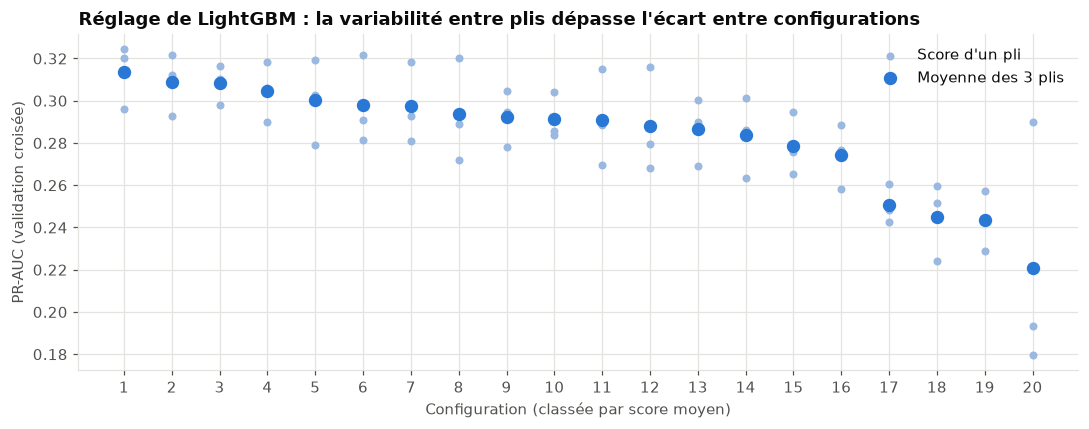

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ranked = cv_res.reset_index(drop=True)
x = np.arange(len(ranked)) + 1
for k in range(3):
    ax.scatter(x, ranked[f"split{k}_test_score"], s=18, color="#9ab8e0", zorder=2,
               label="Score d'un pli" if k == 0 else None)
ax.scatter(x, ranked["mean_test_score"], s=60, color="#2a78d6", zorder=3, label="Moyenne des 3 plis")
ax.set_xticks(x)
ax.set_xlabel("Configuration (classée par score moyen)")
ax.set_ylabel("PR-AUC (validation croisée)")
ax.set_title("Réglage de LightGBM : la variabilité entre plis dépasse l'écart entre configurations",
             loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "06_reglage_lightgbm")
plt.show()

**Lecture**
- La meilleure configuration (score moyen **0,314**) privilégie des arbres **petits** (15 feuilles) et peu d'itérations (200, taux d'apprentissage 0,055). Les moins bonnes échouent dans les deux sens : soit **trop complexes** (127 feuilles et 600 itérations : avec un signal faible sur 5 variables, le modèle **sur-apprend** le bruit), soit **sous-entraînées** (taux d'apprentissage d'environ 0,01-0,02 avec seulement 100 itérations : le modèle n'a pas convergé). Le bon réglage se situe entre les deux.
- **L'écart entre plis est du même ordre que l'écart entre les meilleures configurations** : pour une même configuration, le score varie de ~0,03 d'un pli à l'autre, alors que les 8 premières configurations se tiennent en 0,02. Le classement des meilleures configurations est donc **fragile**.
- Les scores en validation croisée (≈ 0,30) sont inférieurs à ceux de la validation (≈ 0,37). Les plis s'entraînent sur moins de données (0,85 à 1,6 million de lignes) et les jours évalués diffèrent : c'est une autre manifestation de la **non-stationnarité** (notebook 03).

## 5. Comparaison finale sur la validation (jeu `transaction`)

On compare sur la validation :
- la **régression logistique** (référence du notebook 05) ;
- les trois modèles avec leur **meilleure stratégie** de la section 2 ;
- **LightGBM réglé** (meilleure configuration de la validation croisée, réentraîné sur tout le train).

Pour savoir si les écarts sont **significatifs**, on calcule des **intervalles de confiance bootstrap** (300 rééchantillonnages appariés de la validation) de la PR-AUC et de l'écart à la logistique.

In [9]:
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
tuned, s_tuned, d_tuned = fit_and_score("lightgbm", "transaction", TUNING_STRATEGY,
                                        colsample_bytree=1.0, **best_params)
print("Meilleure configuration :", {k: (round(v, 4) if isinstance(v, float) else v)
                                    for k, v in best_params.items()})

logit = make_logistic_regression("transaction").fit(train, y_train)
final_scores = {"Logistique (référence)": logit.predict_proba(val)[:, 1]}
best_strategy = strategies.loc[strategies.groupby("modele")["pr_auc"].idxmax()].set_index("modele")
for name in MODEL_NAMES:
    label = MODEL_LABELS[name]
    final_scores[f"{label} ({best_strategy.loc[label, 'strategie']})"] = \
        scores_tr[(name, best_strategy.loc[label, "strategie"])]
final_scores["LightGBM réglé"] = s_tuned

boot = bootstrap_pr_auc(y_val, final_scores, reference="Logistique (référence)", n_boot=300)
_ = save_results(boot, "06_bootstrap_transaction_validation")
boot

Meilleure configuration : {'learning_rate': np.float64(0.0548), 'min_child_weight': np.float64(0.1241), 'n_estimators': 200, 'num_leaves': 15, 'reg_lambda': np.float64(0.063), 'subsample': np.float64(0.6976)}


,pr_auc,ic_bas,ic_haut,ecart_ref,ecart_ic_bas,ecart_ic_haut,p_meilleur
Logistique (référence),0.0500,0.0390,0.0683,0.0000,0.0000,0.0000,0.0000
Random Forest (sous_echantillonnage),0.3594,0.3121,0.4028,0.3094,0.2668,0.3500,1.0000
XGBoost (aucune),0.3642,0.3227,0.4065,0.3142,0.2739,0.3493,1.0000
LightGBM (ponderation),0.3678,0.3206,0.4104,0.3178,0.2774,0.3527,1.0000
LightGBM réglé,0.3754,0.3301,0.4166,0.3255,0.2847,0.3620,1.0000


Le réglage apporte-t-il un gain réel ? On répète le bootstrap apparié en prenant cette fois **LightGBM par défaut** comme référence.

In [10]:
top = ["LightGBM (ponderation)", "XGBoost (aucune)", "Random Forest (sous_echantillonnage)", "LightGBM réglé"]
boot_top = bootstrap_pr_auc(y_val, {k: final_scores[k] for k in top}, reference="LightGBM (ponderation)", n_boot=300)
boot_top[["pr_auc", "ecart_ref", "ecart_ic_bas", "ecart_ic_haut", "p_meilleur"]]

,pr_auc,ecart_ref,ecart_ic_bas,ecart_ic_haut,p_meilleur
LightGBM (ponderation),0.3678,0.0000,0.0000,0.0000,0.0000
XGBoost (aucune),0.3642,-0.0036,-0.0146,0.0063,0.2367
Random Forest (sous_echantillonnage),0.3594,-0.0084,-0.0214,0.0057,0.1100
LightGBM réglé,0.3754,0.0077,0.0017,0.0140,0.9933


**Lecture**
- Le réglage apporte un gain de **+0,008** de PR-AUC. Il est positif dans 99 % des rééchantillonnages, mais son intervalle est étroit et proche de 0 : le gain est **statistiquement détectable mais pratiquement minime**. Le réglage par défaut était déjà bon.
- XGBoost, Random Forest (sous-échantillonnage) et LightGBM par défaut sont **statistiquement indiscernables** (intervalles de l'écart contenant 0).
- ➡️ Sur ce problème, **le choix des variables pèse bien plus que le choix du modèle ou de ses hyperparamètres** : passer de la logistique aux arbres fait gagner +0,32, le réglage +0,008. Les variables de soldes, elles, font passer de 0,37 à 1,00.

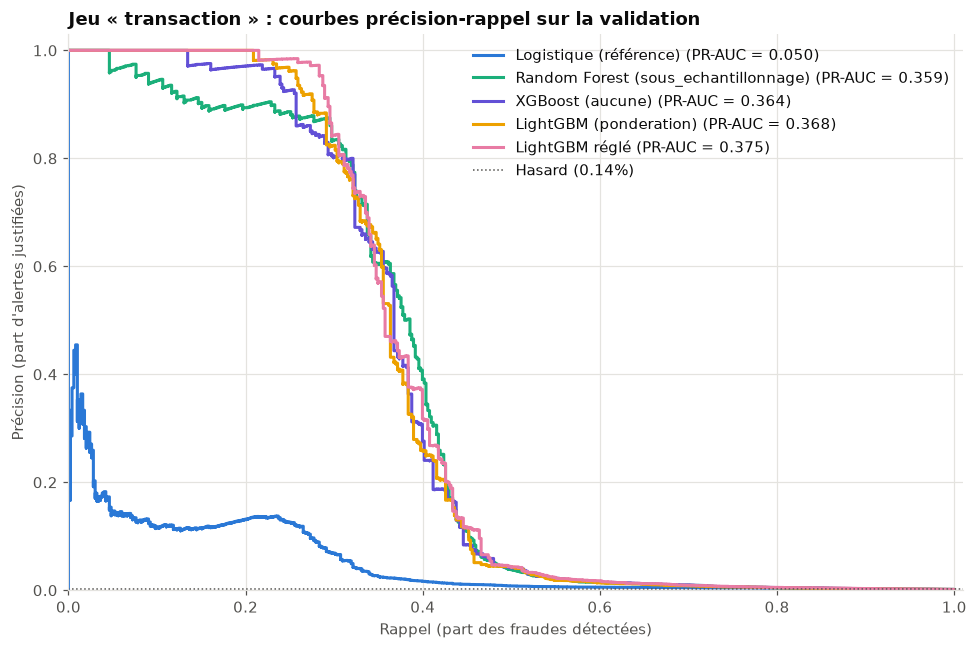

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_pr_curves(ax, final_scores, y_val, legend_loc="upper right")
ax.set_title("Jeu « transaction » : courbes précision-rappel sur la validation", loc="left")
fig.tight_layout()
save_fig(fig, "06_courbes_pr_transaction")
plt.show()

In [12]:
final = compare_models(final_scores, y_val, amounts=amounts_val)
_ = save_results(final, "06_transaction_validation")
final[["pr_auc", "roc_auc", "precision", "rappel", "f2", "n_alertes", "montant_detecte_pct"]]

,pr_auc,roc_auc,precision,rappel,f2,n_alertes,montant_detecte_pct
Logistique (référence),0.0500,0.8173,0.0048,0.6948,0.0235,"71,593.0000",84.8558
Random Forest (sous_echantillonnage),0.3594,0.8595,0.0437,0.4920,0.1612,"5,605.0000",82.8939
XGBoost (aucune),0.3642,0.8749,0.9730,0.2169,0.2568,111.0000,50.6487
LightGBM (ponderation),0.3678,0.8645,0.0079,0.7048,0.0380,"44,187.0000",93.6215
LightGBM réglé,0.3754,0.8782,0.0077,0.7309,0.0370,"47,140.0000",94.1101


**Lecture**
- **Tous les modèles à arbres battent largement la référence** : écart de PR-AUC de +0,31 à +0,33, intervalles de confiance entièrement positifs, meilleurs dans 100 % des rééchantillonnages. La PR-AUC du meilleur modèle (0,375) vaut **260 fois** la prévalence (0,14 %).
- **Forme des courbes** : la précision reste proche de **100 % jusqu'à ~25-30 % de rappel**, puis chute brutalement vers 45 %. Un tiers des fraudes est donc identifiable presque sans fausse alerte. Une vérification hors notebook montre que ces alertes très sûres sont surtout des transactions **entre 1 h et 6 h du matin** : c'est le signal nocturne de **H5** (taux de fraude de 7 % la nuit sur la validation). Le reste des fraudes ressemble aux transactions légitimes sur ces 5 variables.
  > ⚠️ *Note ajoutée après le notebook 08* : ce plateau est en grande partie un **artefact du simulateur**. Entre 3 h et 8 h, il n'existe **aucune** transaction légitime sur la validation et le test, alors que les fraudes sont générées à toute heure. Hors de ces heures, la PR-AUC du modèle tombe à 0,18.
- **Le seuil de 0,5 donne des comportements très différents** selon la stratégie : XGBoost sans pondération lève 111 alertes (précision 97 %, rappel 22 %), LightGBM pondéré en lève 44 000 à 47 000 (précision < 1 %, rappel 70-73 %). La pondération **décale** les probabilités sans changer l'ordre : ce sont les mêmes modèles vus à des seuils différents. Le seuil devra être choisi selon le coût métier (Phase 8).

## 6. Sauvegarde des modèles retenus

Les deux modèles retenus sont réentraînés sous forme de **pipelines complets** (données brutes → probabilité de fraude), directement utilisables par la Phase 8 et par la démo Streamlit :
- `lightgbm_transaction.joblib` : LightGBM réglé, jeu `transaction` ;
- `lightgbm_complet.joblib` : LightGBM pondéré, jeu `complet`.

In [13]:
final_models = {
    "lightgbm_transaction": make_model("lightgbm", "transaction", TUNING_STRATEGY, pos_weight=POS_WEIGHT,
                                       colsample_bytree=1.0, **best_params),
    "lightgbm_complet": make_model("lightgbm", "complet", "ponderation", pos_weight=POS_WEIGHT),
}
MODELS_DIR.mkdir(exist_ok=True)
for file_name, pipe in final_models.items():
    pipe.fit(train, y_train)
    _ = joblib.dump(pipe, MODELS_DIR / f"{file_name}.joblib")

# Contrôle : le pipeline complet reproduit les scores obtenus sur les variables précalculées
check = final_models["lightgbm_transaction"].predict_proba(val)[:, 1]
print(f"Écart maximal pipeline complet / variables précalculées : {np.abs(check - s_tuned).max():.2e}")

Écart maximal pipeline complet / variables précalculées : 0.00e+00


## 7. Conclusions

### Résultats sur la validation

| Jeu de variables | Référence | Meilleur modèle | PR-AUC référence → modèle |
|---|---|---|---|
| `complet` (15 variables) | Règle « compte vidé » | LightGBM pondéré | 0,992 → **1,000** (498/498 fraudes, 1 fausse alerte au seuil 0,5) |
| `transaction` (5 variables) | Régression logistique | LightGBM pondéré et réglé | 0,050 → **0,375** (IC 95 % : 0,330-0,417) |

### Enseignements
1. **Robustesse (étude complet vs transaction)** : retirer les variables de soldes fait chuter la PR-AUC de **1,00 à 0,37**. L'essentiel de la performance « parfaite » vient des soldes, donc des **artefacts du simulateur**. Le jeu `transaction` est le plus proche d'un cas réel.
2. **Non-linéarité** : sur le jeu `transaction`, les arbres font 7 fois mieux que la logistique. Le risque naît des **interactions** entre montant, type et heure, en particulier la nuit (H5).
3. **Question de recherche (déséquilibre)** :
   - pour le **boosting**, la stratégie importe peu (0,33-0,37) ;
   - pour la **Random Forest**, le **sous-échantillonnage** est indispensable (0,28 → 0,36) ;
   - **SMOTE** est inutile, voire nuisible, sur des variables binaires et cycliques ;
   - le **sous-échantillonnage** offre de loin le meilleur rapport performance / coût (entraînement en ~1 s).
4. **Hyperparamètres** : la validation croisée temporelle préfère des modèles **simples**. Le gain du réglage est significatif mais **minime** (+0,008), et inférieur à la variabilité entre périodes.
5. **Méthodologie** : l'effondrement initial de LightGBM était un **problème d'optimisation** (initialisation, hessiennes quasi nulles), identifié en comparant les scores train et validation, et non une limite du modèle.

### Limites
- Toutes les comparaisons portent sur **2 jours de validation** : les intervalles bootstrap supposent l'indépendance des transactions et ignorent la dépendance temporelle.
- Le seuil de 0,5 n'a pas de sens métier : il est optimisé en Phase 8.

### Suite (Phase 8)
- Choix du **seuil par minimisation du coût métier** et sensibilité au coût d'une fausse alerte ;
- **Évaluation finale unique sur le test** des deux modèles retenus (`lightgbm_complet`, `lightgbm_transaction`) ;
- **Robustesse temporelle** sur le jeu de drift (jours 17-30, régime anormal).